# Compulsory Assignment 3: Semantic segmentation

Please fill out the the group name, number, members and optionally the name below.

**Group number**: 20 \
**Group member 1**: Oskar Støre\
**Group member 2**: Magnus Lundetræ Fidje\
**Group member 3**: Håkon Skramstad\
**Group name (optional)**:


# Assignment Submission
To complete this assignment answer the relevant questions in this notebook and write the code required to implement the relevant models. This is the biggest assignment of the semester, and therefore you get two weeks to work on it. However, we reccomend that **you start early**. This assignment has three semi-big sections, each of which build upon the last. So if you delay the assignment until the day before submission, you will most likely fail. This assignment is completed by doing the following. 
* Submit notebook as an .ipynb file to canvas.
* Submit notebook as an .pdf file to canvas.

NOTE: Remember to go through the rules given in the lecture "Introduction to compulsory assignments", as there are many do's and dont's with regard to how you should present the work you are going to submit.


# Introduction 
In the context of transportation, pilots need to identify possible urgent landing areas in forests. 
Therefore, scientists have provided us with aerial photos of the forest and accompanying image 
masks that indicate the presence of birch trees in the images. These masks are binary, with a value of 
0 representing areas without birch trees and a value of 1 indicating the presence of birch trees. Our 
objective is to utilize this dataset to train a model capable of performing semantic segmentation, 
accurately identifying and delineating birch trees in the images.

## Dataset
In this assigmnet you will be given 3200 annotated images. The image, and mask dimensions are 128x128 pixels. With each image there follows an annotation mask where each pixel is classified as `1` (birch tree occurence) or `0` (not birch tree) The test-dataset contains 800 images, where no ground truth masks are given.

## Assignment tasks

1. Familiarising: Before any modelling, visualise examples of the raw data and masks in 
your Jupyter notebook.
2. Basic U-NET: Create a U-Net with optional dropout. Use a proportion of the images 
for validation when training. The minimum requirement is to tune the following 
parameters: number of convolutional filters, dropout and learning rate. Report 
strategies and scores leading up to the final choice. 
3. I recommend adding augmentation (both images and masks) and changing the loss 
function, e.g. implementing F1 loss. Create a plot showing your model's predicted 
mask on some images in the training set and compare to the correct mask.
4. Transfer learning: Create a U-Net where the encoder part of the U-Net uses a pretrained VGG16 (or some other similar pre-trained model)
3. This can be achieved by loading a pre-trained model, dropping the final layer and 
freezing the weights. Add skip connections from the Conv2D layers of the VGG16-
based encoder to the expansion layers of the decoder.

# Library imports
Feel free to import other packages as needed.

In [1]:
import time
from tqdm import tqdm # Cool progress bar
import random
import numpy as np
import pandas as pd
import h5py
import cv2
import re
from IPython.display import Image
import matplotlib.pyplot as plt
import seaborn as sns
from utilities import *
from visualization import *
SEED = 458 # Feel free to set another seed if you want to
RNG = np.random.default_rng(SEED) # Random number generator
tf.random.set_seed(SEED)

from tensorflow.keras.metrics import FalseNegatives, FalsePositives, TrueNegatives, TruePositives
from visualization import plot_training_history

# had to use metricwrapper, because Keras gave other names that didn't fit with keys from vizualization.py
from tensorflow.keras.metrics import MeanMetricWrapper

I0000 00:00:1792944473.131415    5653 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792944473.133700    5653 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792944473.411683    5653 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792944474.493191    5653 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

# Data loading

Load the data from the HDF5 file `tree_train.h5` and `tree_test.h5` that is available on Canvas.
The data should be loaded in the same manner as in CA2. 

In [12]:
# path to the datasets
# GJØR OM TIL FUNKSJON SENERE
from pathlib import Path
path_train = "/home/skramstad/Documents/DAT300/Assignments/CA3/data/tree_train.h5"
path_test = "/home/skramstad/Documents/DAT300/Assignments/CA3/data/tree_test.h5"

labels = {
    0: "not birch tree",
    1: "birch tree occurence"
}

with h5py.File(path_train, 'r') as f:
    print('Datasets in file:', list(f.keys()))
    X_train = np.asanyarray(f['X'])
    y_train = np.asanyarray(f['y'])

with h5py.File(path_test, 'r') as f:
    print('Datasets in file:', list(f.keys()))
    X_test = np.asanyarray(f['X'])



print(X_train.shape)
print(y_train.shape)
print(X_test.shape)

Datasets in file: ['X', 'y']
Datasets in file: ['X']
(3200, 128, 128, 3)
(3200, 128, 128, 1)
(800, 128, 128, 3)


# Visualization

Plot a few samples images and masks. \
Feel free to visualize any other aspects of the dataset that you feel are relevant. 

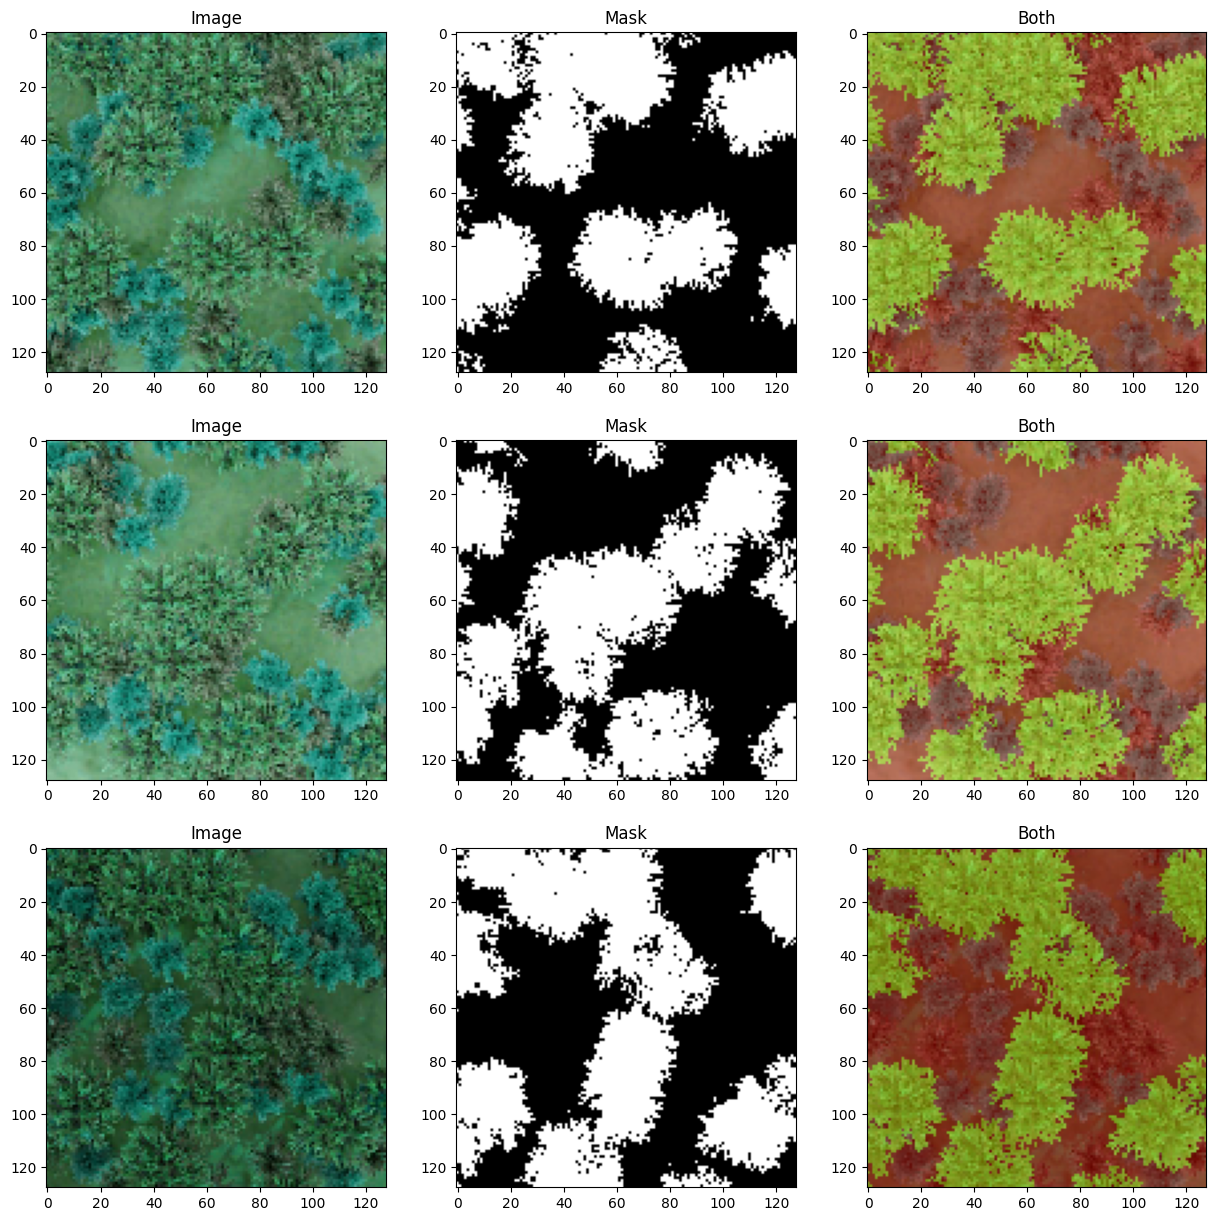

In [31]:
plt.figure(figsize=(15,15))

for i in range(3):

    plt.subplot(3,3,i*3+1)
    plt.imshow(X_train[i],vmin=0, vmax=1)
    plt.title('Image')


    plt.subplot(3,3,i*3 +2)
    plt.imshow(y_train[i], cmap='gray', vmin=0, vmax=1)
    plt.title('Mask')


    plt.subplot(3,3,i*3 +3)
    plt.imshow(X_train[i])
    plt.imshow(y_train[i],alpha=0.4,cmap='autumn', vmin=0, vmax=1)
    plt.title('Both')


plt.show()

# Preprocessing

Preprocess the dataset in whatever ways you think are helpful. \
Tips: Perhaps you preprocess the different models in different ways?

In [14]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32')/255.0

y_train = y_train.astype('float32')

# Part 1: Implementing U-net

## Intersection over Union

The IoU score is a popular metric in both segmentation and object detection problems. 

If you want to use the `plot_training_history` function in the `visualization.py` library remember to compile the model with the TP, TN, FP, FN metrics such that you can estimate the *Intersection-over-Union*. **However, it is voluntary to estimate IoU**

See example below:

```python
from tensorflow.keras.metrics import FalseNegatives, FalsePositives, TrueNegatives, TruePositives
from utilities import F1_score, 
from visualization import plot_training_history, 
...
model.compile(optimizer='Something', 
                  loss='Something else', 
                  metrics=[FalseNegatives(),
                           FalsePositives(),
                           TrueNegatives(),
                           TruePositives(),
                           F1_score,
                           OtherMetricOfChoice])

training_history = model.fit(X_train, y_train, ...)
plot_training_history(training_history)
```

You have also been provided with a custom F1-score metric in the `utilities.py` library, which is specific for image segmentation. **This is mandatory to use when compiling the model**.


## Task 1.1 Model implementation

Implement the classical U-net structure that you have learned about in the lectures. Feel free to experiment with the number of layers, loss-function, batch-normalization, etc. **Remember to compile with the F1-score metric**. 


### U-net

In [15]:
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, Activation, MaxPooling2D, Dropout, Conv2DTranspose, concatenate
from tensorflow.keras.models import Model

In [ ]:
"""
Version of U-Net with dropout and size preservation (padding= 'same')
""" 
def conv2d_block(input_tensor, n_filters, kernel_size = 3, batchnorm = True):
    """Function to add 2 convolutional layers with the parameters passed to it"""
    # first layer
    x = Conv2D(filters = n_filters, kernel_size = (kernel_size, kernel_size),\
              kernel_initializer = 'he_normal', padding = 'same')(input_tensor)
    if batchnorm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # second layer
    x = Conv2D(filters = n_filters, kernel_size = (kernel_size, kernel_size),\
              kernel_initializer = 'he_normal', padding = 'same')(x)
    if batchnorm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    return x


def get_unet(input_img, n_filters = 16, dropout = 0.1, batchnorm = True, n_classes = 2):
    # Contracting Path
    c1 = conv2d_block(input_img, n_filters * 1, kernel_size = 3, batchnorm = batchnorm)
    p1 = MaxPooling2D((2, 2))(c1)
    p1 = Dropout(dropout)(p1)
    
    c2 = conv2d_block(p1, n_filters * 2, kernel_size = 3, batchnorm = batchnorm)
    p2 = MaxPooling2D((2, 2))(c2)
    p2 = Dropout(dropout)(p2)
    
    c3 = conv2d_block(p2, n_filters * 4, kernel_size = 3, batchnorm = batchnorm)
    p3 = MaxPooling2D((2, 2))(c3)
    p3 = Dropout(dropout)(p3)
    
    c4 = conv2d_block(p3, n_filters * 8, kernel_size = 3, batchnorm = batchnorm)
    p4 = MaxPooling2D((2, 2))(c4)
    p4 = Dropout(dropout)(p4)
    
    c5 = conv2d_block(p4, n_filters = n_filters * 16, kernel_size = 3, batchnorm = batchnorm)
    
    # Expansive Path
    u6 = Conv2DTranspose(n_filters * 8, (3, 3), strides = (2, 2), padding = 'same')(c5)
    u6 = concatenate([u6, c4])
    u6 = Dropout(dropout)(u6)
    c6 = conv2d_block(u6, n_filters * 8, kernel_size = 3, batchnorm = batchnorm)
    
    u7 = Conv2DTranspose(n_filters * 4, (3, 3), strides = (2, 2), padding = 'same')(c6)
    u7 = concatenate([u7, c3])
    u7 = Dropout(dropout)(u7)
    c7 = conv2d_block(u7, n_filters * 4, kernel_size = 3, batchnorm = batchnorm)
    
    u8 = Conv2DTranspose(n_filters * 2, (3, 3), strides = (2, 2), padding = 'same')(c7)
    u8 = concatenate([u8, c2])
    u8 = Dropout(dropout)(u8)
    c8 = conv2d_block(u8, n_filters * 2, kernel_size = 3, batchnorm = batchnorm)
    
    u9 = Conv2DTranspose(n_filters * 1, (3, 3), strides = (2, 2), padding = 'same')(c8)
    u9 = concatenate([u9, c1])
    u9 = Dropout(dropout)(u9)
    c9 = conv2d_block(u9, n_filters * 1, kernel_size = 3, batchnorm = batchnorm)
    
    outputs = Conv2D(n_classes, (1, 1), activation='sigmoid')(c9)
    model = Model(inputs=[input_img], outputs=[outputs])
    return model

input_img = Input(shape=(128,128,3))
U_net_v1 = get_unet(input_img, n_filters=20, dropout=0.25, batchnorm=True, n_classes=1)

U_net_v1.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 128, 128,  │        560 │ input_layer_1[0]… │
│                     │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         80 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 128, 128,  │      3,620 │ activation_18[0]… │
│                     │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         80 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 64, 64,    │          0 │ activation_19[0]… │
│ (MaxPooling2D)      │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64, 64,    │          0 │ max_pooling2d_4[… │
│                     │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 64, 64,    │      7,240 │ dropout_8[0][0]   │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        160 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_20       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 64, 64,    │     14,440 │ activation_20[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        160 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_21       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 32, 32,    │          0 │ activation_21[0]… │
│ (MaxPooling2D)      │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 32, 32,    │          0 │ max_pooling2d_5[

 Total params: 3,379,661 (12.89 MB)

 Trainable params: 3,375,981 (12.88 MB)

 Non-trainable params: 3,680 (14.38 KB)

## Task 1.2 Train the model, and plot the training history
Feel free to use the `plot_training_history` function from the provided library `utilities.py`

### Training the model

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

U_net_v1.compile(optimizer=optimizer,
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[FalseNegatives(name='false_negatives'),
                       FalsePositives(name='false_positives'),
                       TrueNegatives(name='true_negatives'),
                       TruePositives(name='true_positives'),
                       MeanMetricWrapper(F1_score, name='F1_score'),
                       'accuracy'])

history_v1 = U_net_v1.fit(X_train,y_train,batch_size=64,epochs=10,validation_split=1/6)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 113s 3s/step - F1_score: 0.8081 - accuracy: 0.8212 - false_negatives: 3414604.0000 - false_positives: 4395842.0000 - loss: 0.3854 - true_negatives: 19452130.0000 - true_positives: 16417170.0000 - val_F1_score: 0.7076 - val_accuracy: 0.7366 - val_false_negatives: 1177748.0000 - val_false_positives: 1126774.0000 - val_loss: 0.6033 - val_true_negatives: 3645684.0000 - val_true_positives: 2798850.0000
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 110s 3s/step - F1_score: 0.8944 - accuracy: 0.9028 - false_negatives: 1864420.0000 - false_positives: 2380131.0000 - loss: 0.2413 - true_negatives: 21467838.0000 - true_positives: 17967356.0000 - val_F1_score: 0.7341 - val_accuracy: 0.7859 - val_false_negatives: 1386060.0000 - val_false_positives: 486804.0000 - val_loss: 0.4617 - val_true_negatives: 4285654.0000 - val_true_positives: 2590538.0000
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 106s 3s/step - F1_score: 0.9067 - accuracy: 0.9141 - false_negatives: 1597818.0000 - 

### Plotting performance

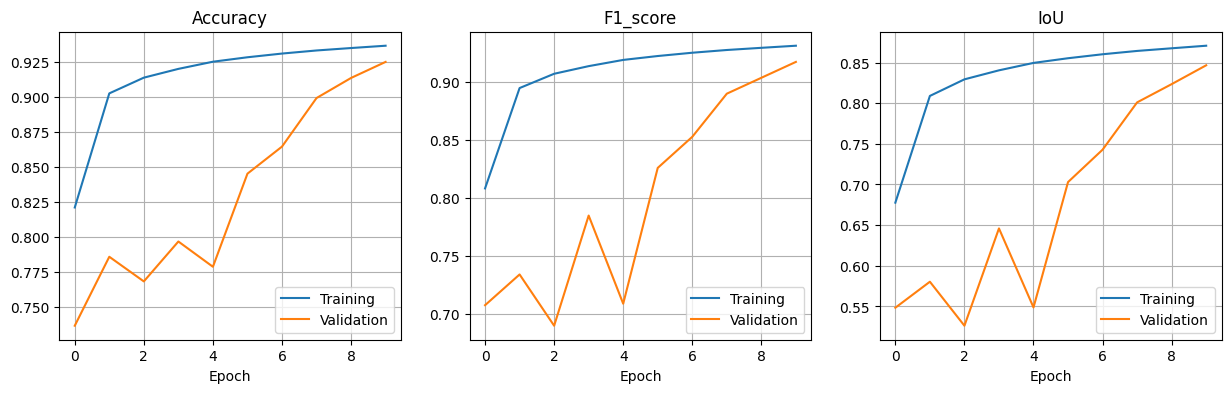

In [ ]:
plot_training_history(history_v1)

### Trying differen U-net configurations
Trying with lower dropout

In [34]:
U_net_v2 = get_unet(input_img, n_filters=20, dropout=0.1, batchnorm=True, n_classes=1)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

U_net_v2.compile(optimizer=optimizer,
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[FalseNegatives(name='false_negatives'),
                       FalsePositives(name='false_positives'),
                       TrueNegatives(name='true_negatives'),
                       TruePositives(name='true_positives'),
                       MeanMetricWrapper(F1_score, name='F1_score'),
                       'accuracy'])

history_v2 = U_net_v2.fit(X_train,y_train,batch_size=64,epochs=10,validation_split=1/6)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 118s 3s/step - F1_score: 0.8055 - accuracy: 0.8347 - false_negatives: 4155267.0000 - false_positives: 3064246.0000 - loss: 0.3626 - true_negatives: 20783724.0000 - true_positives: 15676507.0000 - val_F1_score: 4.9435e-04 - val_accuracy: 0.5456 - val_false_negatives: 3975536.0000 - val_false_positives: 135.0000 - val_loss: 2.2838 - val_true_negatives: 4772323.0000 - val_true_positives: 1062.0000
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 115s 3s/step - F1_score: 0.9019 - accuracy: 0.9096 - false_negatives: 1705093.0000 - false_positives: 2242827.0000 - loss: 0.2237 - true_negatives: 21605144.0000 - true_positives: 18126682.0000 - val_F1_score: 0.0282 - val_accuracy: 0.5511 - val_false_negatives: 3919973.0000 - val_false_positives: 7687.0000 - val_loss: 1.0050 - val_true_negatives: 4764771.0000 - val_true_positives: 56625.0000
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 119s 3s/step - F1_score: 0.9114 - accuracy: 0.9186 - false_negatives: 1553686.0000 - false_p

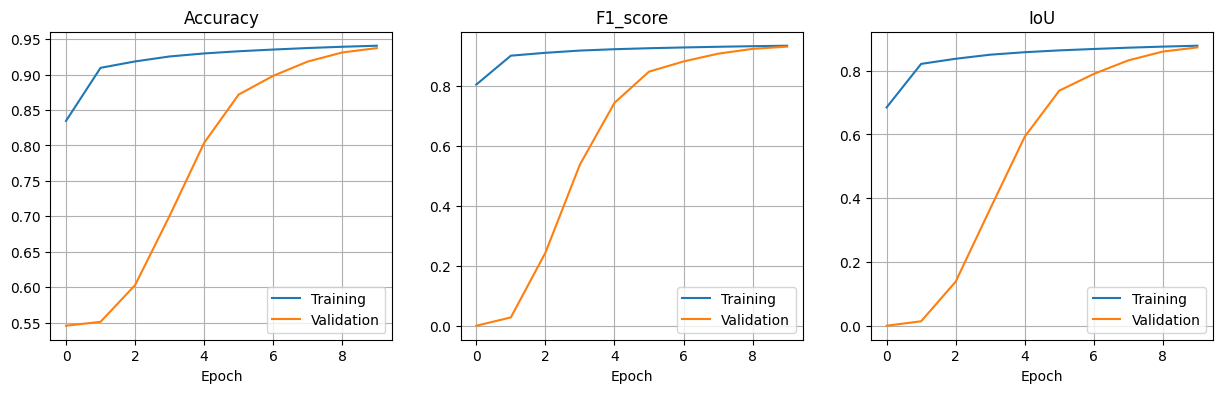

In [35]:
plot_training_history(history_v2)

Trying now with more filters

In [36]:
U_net_v3 = get_unet(input_img, n_filters=32, dropout=0.1, batchnorm=True, n_classes=1)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

U_net_v3.compile(optimizer=optimizer,
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[FalseNegatives(name='false_negatives'),
                       FalsePositives(name='false_positives'),
                       TrueNegatives(name='true_negatives'),
                       TruePositives(name='true_positives'),
                       MeanMetricWrapper(F1_score, name='F1_score'),
                       'accuracy'])

history_v3 = U_net_v3.fit(X_train,y_train,batch_size=64,epochs=10,validation_split=1/6)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 243s 6s/step - F1_score: 0.8497 - accuracy: 0.8495 - false_negatives: 2271162.0000 - false_positives: 4301881.0000 - loss: 0.3475 - true_negatives: 19546090.0000 - true_positives: 17560612.0000 - val_F1_score: 0.6943 - val_accuracy: 0.7464 - val_false_negatives: 1457026.0000 - val_false_positives: 762125.0000 - val_loss: 0.5472 - val_true_negatives: 4010333.0000 - val_true_positives: 2519572.0000
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 244s 6s/step - F1_score: 0.9062 - accuracy: 0.9131 - false_negatives: 1507174.0000 - false_positives: 2290104.0000 - loss: 0.2174 - true_negatives: 21557864.0000 - true_positives: 18324600.0000 - val_F1_score: 0.0018 - val_accuracy: 0.5459 - val_false_negatives: 3973055.0000 - val_false_positives: 74.0000 - val_loss: 1.2590 - val_true_negatives: 4772384.0000 - val_true_positives: 3543.0000
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 236s 6s/step - F1_score: 0.9162 - accuracy: 0.9228 - false_negatives: 1399084.0000 - false_po

KeyboardInterrupt: 

In [ ]:
plot_training_history(history_v3)

Trying with lower learning rate

In [ ]:
U_net_v4= get_unet(input_img, n_filters=20, dropout=0.1, batchnorm=True, n_classes=1)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)

U_net_v4.compile(optimizer=optimizer,
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[FalseNegatives(name='false_negatives'),
                       FalsePositives(name='false_positives'),
                       TrueNegatives(name='true_negatives'),
                       TruePositives(name='true_positives'),
                       MeanMetricWrapper(F1_score, name='F1_score'),
                       'accuracy'])

history_v4 = U_net_v4.fit(X_train,y_train,batch_size=64,epochs=10,validation_split=1/6)

In [ ]:
plot_training_history(history_v4)

## Task 1.3 Visualize model predictions

Make a plot that illustrates the original image, the predicted mask, and the ground truth mask. 

### Plotting

In [ ]:
predicted= U_net_v1.predict(X_train)

pred_masks = (predicted > 0.5).astype('float32')

100/100 ━━━━━━━━━━━━━━━━━━━━ 30s 299ms/step


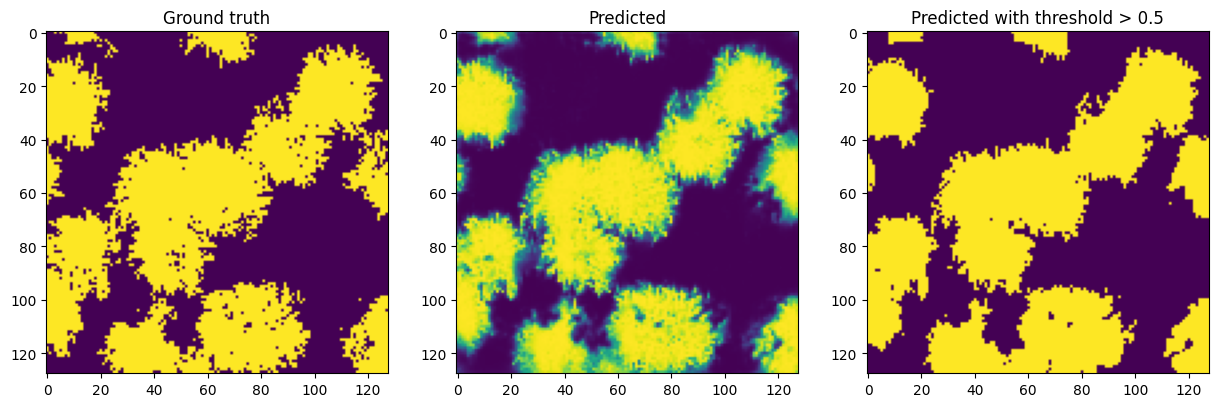

In [ ]:
plt.figure(figsize=(15,15))

for i in range(3):
    plt.subplot(1,3,i*3+1)
    plt.imshow(y_train[i], vmin=0, vmax=1)
    plt.title('Ground truth')

    plt.subplot(1,3,i*3+2)
    plt.imshow(predicted[i], vmin=0, vmax=1)
    plt.title('Predicted')

    plt.subplot(1,3,i*3+3)
    plt.imshow(pred_masks[i], vmin=0, vmax=1)
    plt.title('Predicted with threshold > 0.5')

plt.show()

# Part 2: Implementing U-net with transfer learning

Implement a model with the U-net structure that you have learned about in the lectures, but now with a pre-trained backbone. There are many pre-trained back-bones to choose from. Pick freely from the selection here [tf.keras.applications](https://www.tensorflow.org/api_docs/python/tf/keras/applications), or here [Keras model scores](https://keras.io/api/applications/) (nicer table in the second link). Feel free to experiment with the number of layers, loss-function, batch-normalization, etc. Many of the backbones available are quite big, so you might find it quite time-consuming to train them on your personal computers.


#### For those with a dedicated graphics card (NVIDIA and AMD) Tensorflow or PyTorch (not syllabus)
And wants to experiment with their own compute resources (can be alot of fun)\
Tensorflow: https://learn.microsoft.com/en-us/windows/ai/directml/gpu-tensorflow-plugin \
PyTorch: https://learn.microsoft.com/en-us/windows/ai/directml/pytorch-windows

## Task 2.1 Transfer learning model implementation

Implement a U-net model utilizing the pre-trained weights of a publically available network. **Remember to compile with the F1-score metric**.

### Transfer learning with U-net

4. Transfer learning: Create a U-Net where the encoder part of the U-Net uses a pretrained VGG16 (or some other similar pre-trained model)
3. This can be achieved by loading a pre-trained model, dropping the final layer and 
freezing the weights. Add skip connections from the Conv2D layers of the VGG16-
based encoder to the expansion layers of the decoder.

In [ ]:
# importing VGG16 from Keras
from keras.applications.vgg16 import VGG16

encoder = VGG16(weights='imagenet',
                include_top=False,
                input_shape=()) #input shape needs (224, 244, 3)

## Task 2.2 Train the transfer learning model and plot the training history

Feel free to use the `plot_training_history` function from the provided library `utilities.py`

### Training

### Plotting

# Discussion

**Question 1: Which model architectures did you explore, and what type of hyperparameter optimization did you try?**  

**Answer 1:**  

**Question 2: What where the biggest challenges with this assignment?**  

**Answer 2:**  


# Appendix
Links to fun and interessting learning resources \
(not so much for this compulsary assignment, more for your own learning and interests):

- <a href="https://streamlit.io/">Streamlit</a>
- <a href="https://github.com/mlabonne/llm-datasets?tab=readme-ov-file">LLM-datasets</a>
- <a href="https://github.com/PacktPublishing/Hands-On-Graph-Neural-Networks-Using-Python">Hands-On Graph Neural Networks Using Python</a>
- <a href="https://github.com/mlabonne/llm-course">LLM Course</a>
- <a href="https://bbycroft.net/llm">LLM by Bycroft</a>
- <a href="https://groq.com/">Groq</a>
- <a href="https://unstructured.io/?fob=kxzdntwfMj4TVNSV">Unstructured.io</a>
- <a href="https://colab.research.google.com/notebooks/tpu.ipynb#scrollTo=a_rjVo-RAoYd">Google Colab TPU Notebook</a>
- <a href="https://github.com/langchain-ai/langgraph/tree/main">LangGraph RAG Agent Llama3 Local</a>
- <a href="https://python.langchain.com/docs/how_to/">LangChain Python Docs</a>
- <a href="https://www.nomic.ai/blog/posts/nomic-embed-text-v1">Nomic Embed Text v1</a>
- <a href="https://duckdb.org/docs/api/python/overview.html">DuckDB Python API Overview</a>
- <a href="https://jsoncrack.com/editor">JSON Crack Editor</a>
- <a href="https://learn.microsoft.com/en-us/azure/data-factory/transform-data-machine-learning-service">Azure Data Factory Machine Learning Service</a>

- <a href="https://learn.microsoft.com/en-us/azure/databricks/machine-learning/">Azure Databricks Machine Learning</a>
- <a href="https://github.com/katanaml">Katana ML - Machine Learning for Business Automation</a>
- <a href="https://deckgl.readthedocs.io/en/latest/">Pydeck - High-scale spatial rendering in Python, powered by deck.gl</a>




